## Langraph核心研究

In [1]:
from typing import TypedDict
from langgraph.constants import END, START
from langgraph.graph import StateGraph

class InputState(TypedDict):
    user_input: str # 用户输入
    
class OutputState(TypedDict):
    graph_output: str # 图的输出
    
class OverallState(TypedDict):
    foo: str # 当前消息内容
    user_input: str # 用户输入
    graph_output: str # 图的输出
    bar:str # 当前消息内容

In [2]:
def node_1(state:InputState) ->OverallState:
    return {"foo": state["user_input"] +" > 学院"} # type:ignore

def node_2(state:OverallState) ->OverallState:
    return {"bar": state["foo"]+" > 非常"}

def node_3(state:OverallState) ->OutputState:
    return {"graph_output": state["bar"]+" > 靠谱"}

In [3]:
graph = StateGraph(state_schema=OverallState, input_schema=InputState, output_schema=OutputState)

In [4]:
graph.add_node("node_1", node_1)
graph.add_node("node_2", node_2)
graph.add_node("node_3", node_3)

graph.add_edge(START, "node_1")
graph.add_edge("node_1", "node_2")
graph.add_edge("node_2", "node_3")
graph.add_edge("node_3", END)

app = graph.compile()

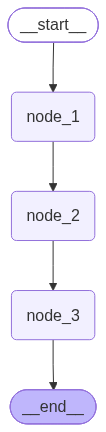

In [5]:
app

In [6]:
res = app.invoke({"user_input":"大模型开发"})

c:\Users\21566\anaconda3\envs\ai-langchain1.0\Lib\site-packages\langsmith\_internal\_agent_addressing.py:61: LangSmithBetaWarning: Agent addressing (`agent_id` / `agent_environment`) is in beta and is enabled per workspace. A workspace without it rejects the run, so the trace is lost rather than falling back to a project. The behavior may change without notice.
  _warn_once(


In [7]:
res

{'graph_output': '大模型开发 > 学院 > 非常 > 靠谱'}

In [8]:
from typing import Annotated, TypedDict
from operator import add
from langchain_core.messages import AnyMessage, AIMessage
from langgraph.graph import StateGraph, START
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]  # 追加（去重合并）
    list_field: Annotated[list[int], add]                # 追加（列表拼接）
    extra_field: int                                     # 覆盖

def node1(state: State):
    return {"messages": [AIMessage("Hello!")], "list_field": [10], "extra_field": 10}

def node2(state: State):
    return {"messages": [AIMessage("LangGraph!")], "list_field": [20], "extra_field": 20}

graph = (
    StateGraph(State)
    .add_node("node1", node1)
    .add_node("node2", node2)
    .add_edge(START, "node1")
    .add_edge("node1", "node2")
    .compile()
)

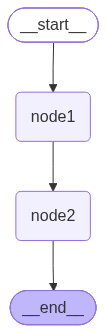

In [9]:
graph

In [ ]:
result = graph.invoke({
    "messages": [{"role": "user", "content": "Hi"}],  # {"role": "user", "content": "Hi"},AIMessage("Hello!"),AIMessage("LangGraph!")
    "list_field": [1, 2, 3],  # 1,2,3,10, 20
    "extra_field": 100 # 20
})

In [11]:
result

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='edcd0c86-f5ab-451b-a626-c2f188713da6'),
  AIMessage(content='Hello!', additional_kwargs={}, response_metadata={}, id='299f0e3c-4ed3-4562-8e31-dd068ec73db3', tool_calls=[], invalid_tool_calls=[]),
  AIMessage(content='LangGraph!', additional_kwargs={}, response_metadata={}, id='fb584d47-5b06-4c79-9c4b-0266f158e86d', tool_calls=[], invalid_tool_calls=[])],
 'list_field': [1, 2, 3, 10, 20],
 'extra_field': 20}

## Node节点

C:\Users\21566\AppData\Local\Temp\ipykernel_8504\3661422784.py:25: LangGraphDeprecatedSinceV10: `config_schema` is deprecated and will be removed. Please use `context_schema` instead. Deprecated in LangGraph V1.0 to be removed in V2.0.
  StateGraph(State, config_schema=ConfigSchema) #type: ignore


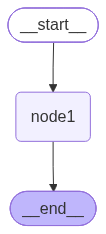

In [12]:
from langchain_core.runnables import RunnableConfig
from langgraph.cache.memory import InMemoryCache
from langgraph.types import CachePolicy
import time

# 状态类型
class State(TypedDict):
    number:int
    user_id: str

# 配置的参数类型
class ConfigSchema(TypedDict):
    user_id: str

def node1(state: State, config:RunnableConfig):
    time.sleep(5) # 暂停5秒
    user_id = config["configurable"]["user_id"] #type: ignore
    if user_id=="admin": 
        return {"number": state["number"] + 888, "user_id":user_id}
    
    return {"number": state["number"] + 1, "user_id":user_id}


graph = (
    StateGraph(State, config_schema=ConfigSchema) #type: ignore
    .add_node("node1", node1,cache_policy=CachePolicy(ttl=10)) # 添加缓存策略
    .add_edge(START, "node1")
    .add_edge("node1", END)
    .compile(cache=InMemoryCache())
)
graph

In [13]:
res = graph.invoke({"number": 0}, config={"configurable": {"user_id": "admin"}})
res

{'number': 888, 'user_id': 'admin'}

In [14]:
res = graph.invoke({"number": 0}, config={"configurable": {"user_id": "admin"}})
res

{'number': 888, 'user_id': 'admin'}

In [17]:
res = graph.invoke({"number": 0}, config={"configurable": {"user_id": "admin"}})
res

{'number': 888, 'user_id': 'admin'}

In [18]:
res = graph.invoke({"number": 10}, config={"configurable": {"user_id": "admin"}})
res

{'number': 898, 'user_id': 'admin'}

## 条件边

In [19]:
from typing import TypedDict,Literal
from langchain_core.runnables import RunnableConfig
from langgraph.constants import START, END
from langgraph.graph import StateGraph

# 配置状态
class State(TypedDict):
    number:int
    
def node_1(state:State):
    return {"number":state["number"] + 1}

def routing_function(state:State)->Literal["node_1",END]:
    if state["number"] < 10:
        return "node_1"
    return END

builder = StateGraph(State)
builder.add_node("node_1", node_1)
builder.add_conditional_edges(START, routing_function)
builder.add_edge("node_1", END)
graph = builder.compile()


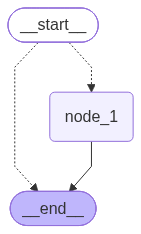

In [21]:
graph

In [23]:
res = graph.invoke({"number": 5})
print(res)

{'number': 6}


In [24]:
## 课堂练习
from typing import TypedDict,Literal
from langchain_core.runnables import RunnableConfig
from langgraph.constants import START, END
from langgraph.graph import StateGraph

# 配置状态
class State(TypedDict):
    color:str
    output:str
    
def node_1(state:State):
    return {"output":"红色节点处理的结果"}

def node_2(state:State):
    return {"output":"蓝色节点处理的结果"}

def routing_function(state:State)->Literal["node_1","node_2"]:
    if state["color"] =="red":
        return "node_1"
    else:
        return "node_2"

builder = StateGraph(State)
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_conditional_edges(START, routing_function)
builder.add_edge("node_1", END)
builder.add_edge("node_2", END)
graph = builder.compile()


In [31]:
res = graph.invoke({"color":"red"})
print(res)

{'color': 'red', 'output': '红色节点处理的结果'}


In [32]:
res = graph.invoke({"color":"blue"})
print(res)

{'color': 'blue', 'output': '蓝色节点处理的结果'}


In [ ]:
graph

Failed to send compressed multipart ingest: Connection error caused failure to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. Please confirm your internet connection. ConnectionError(MaxRetryError('HTTPSConnectionPool(host=\'api.smith.langchain.com\', port=443): Max retries exceeded with url: /runs/multipart (Caused by ReadTimeoutError("HTTPSConnectionPool(host=\'api.smith.langchain.com\', port=443): Read timed out. (read timeout=3)"))'))
Content-Length: 1531
API Key: lsv2_********************************************d8trace=01a13e32-ac26-79a3-87d0-d377f60d30f9,id=01a13e32-ac26-79a3-87d0-d377f60d30f9; trace=01a13e32-ac26-79a3-87d0-d377f60d30f9,id=01a13e32-ac28-7b70-a847-ac90cdb77283; trace=01a13e32-ac26-79a3-87d0-d377f60d30f9,id=01a13e32-ac28-7b70-a847-aca092e07632; trace=01a13e32-ac26-79a3-87d0-d377f60d30f9,id=01a13e32-ac28-7b70-a847-aca092e07632; trace=01a13e32-ac26-79a3-87d0-d377f60d30f9,id=01a13e32-ac28-7b70-a847-ac90cdb77283; trace=01a13e32-ac26-79a3-87d0-d37

## Send的使用

In [3]:
from typing import TypedDict,Literal, Annotated
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
import operator

class State(TypedDict):
    inputs: str
    outputs: Annotated[list[str], operator.add] # reducer: 列表拼接
    
def upper(state: State) -> State:
    # 从 Send 传入的临时字段 "item" 读取
    transformed = state["inputs"].upper() + "!" # HELLO!
    return {"outputs": [transformed]} #{"outputs": ["HELLO!"]}

def lower(state: State) -> State:
    # 从 Send 传入的临时字段 "item" 读取
    transformed = state["inputs"].lower() + "%" # hello%
    return {"outputs": [transformed]} #{"outputs": ["hello%"]}

def fan_out(state: State)->Literal["upper","lower"]:
    # 对 inputs 中元素，发送两个任务
    return [
        Send("upper", {"inputs": state["inputs"]}),
        Send("lower", {"inputs": state["inputs"]})
    ]
# 构建图
builder = StateGraph(State)
builder.add_node("upper", upper)
builder.add_node("lower", lower)
builder.add_conditional_edges(START, fan_out)
builder.add_edge("upper", END)
builder.add_edge("lower", END)
graph = builder.compile() #{"outputs": ["HELLO!", "hello%"]}

In [4]:
res = graph.invoke({"inputs": "Hello"})
res 

c:\Users\21566\anaconda3\envs\ai-langchain1.0\Lib\site-packages\langsmith\_internal\_agent_addressing.py:61: LangSmithBetaWarning: Agent addressing (`agent_id` / `agent_environment`) is in beta and is enabled per workspace. A workspace without it rejects the run, so the trace is lost rather than falling back to a project. The behavior may change without notice.
  _warn_once(


{'inputs': 'Hello', 'outputs': ['HELLO!', 'hello%']}

In [6]:
graph = builder.compile()

# 🌟 只获取纯文本的 Mermaid 代码，不涉及任何网络请求或浏览器
mermaid_code = graph.get_graph().draw_mermaid()
print(mermaid_code)

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	upper(upper)
	lower(lower)
	__end__([<p>__end__</p>]):::last
	__start__ -.-> lower;
	__start__ -.-> upper;
	lower --> __end__;
	upper --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



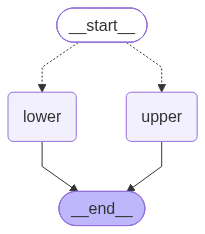

In [7]:
graph

## Command的使用

In [13]:
from typing import TypedDict,Literal, Annotated
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command
import operator

class State(TypedDict):
    inputs: str
    outputs: str
    
def tech(state: State) -> State:
    return {"outputs": state["inputs"]+"技术支持！"}

def chichat(state: State) -> State:
    return {"outputs": state["inputs"]+"闲聊！"}

# 路由节点，判断用户的输入状态，用Command来决定下一步走向
def router(state: State)->Command[Literal["tech","chichat"]]:
    input_content = state["inputs"]
    destination = None
    change_state = None
    if "技术" in input_content:
        destination = "tech"
        change_state = {"inputs": input_content+" 跳转到技术支持节点"}
    else:
        destination = "chichat"
        change_state = {"inputs": input_content+" 跳转到闲聊节点"}
        
    # goto: 下一步节点
    # update: 更新状态
    return Command(goto=destination, update=change_state)
    
    
# 构建图
builder = StateGraph(State)
builder.add_node("tech", tech)
builder.add_node("chichat", chichat)
builder.add_node("router", router)

builder.add_edge(START, "router")
builder.add_edge("tech", END)
builder.add_edge("chichat", END)

graph = builder.compile() 

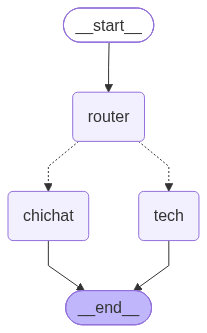

In [14]:
graph

In [15]:
res = graph.invoke({"inputs": "这个产品有点质量问题，我需要技术帮助！"})
print(res)

{'inputs': '这个产品有点质量问题，我需要技术帮助！ 跳转到技术支持节点', 'outputs': '这个产品有点质量问题，我需要技术帮助！ 跳转到技术支持节点技术支持！'}


### Send和Command的区别
- 1. Send是一对多并行分发，而Command是状态跟新和路由
- 2. Send是在条件函数中返回，而Command是在节点函数中或者工具函数中返回
- 3. Send具有并行能力，而Command不具备，总是指定一个单一的节点
- 4. Send可以为每个被发送的节点定制独立的初始状态，而Command可以更新全局的State

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START
from langgraph.types import Command
from langgraph.constants import END

class State(TypedDict):
    inputs: str
    outputs: str

def A(state: State) -> State:
    return {"outputs": state["inputs"]+"产品！"}

def B(state: State) -> State:
    return {"outputs": state["inputs"]+"售后！"}

def C(state: State) -> State:
    return {"outputs": state["inputs"]+"政策！"}
def D(state: State) -> State:
    return {"outputs": state["inputs"]+"人工处理！"}



def sum_all(state: State) -> State:
    return {"outputs": state["inputs"]}

def Router(state: State) -> Command[Literal["A", "B","C", "D"]]:
    input_content = state["inputs"]
    destination = None
    change_state = None
    
    #意图识别【关键词|微调模型|JEV】
    if "产品" in input_content:
        destination = "A"
        change_state = {"inputs": "处理产品问题"}
    elif "售后" in input_content:
        destination = "B"
        change_state = {"inputs": "处理售后问题"}
    elif "政策" in input_content:
        destination = "C"
        change_state = {"inputs": "处理政策问题"}
    else:
        destination = "D"
        change_state = {"inputs": "正在转人工处理"}
    # goto: 下一步节点
    # update: 更新状态
    return Command(goto=destination, update=change_state)
builder = StateGraph(State)
builder.add_node("Router", Router)
builder.add_node("A", A)
builder.add_node("B",B)
builder.add_node("C",C)
builder.add_node("D",D)
builder.add_node("sum_all",sum_all)

builder.add_edge(START, "Router")
builder.add_edge("A", "sum_all")
builder.add_edge("B", "sum_all")
builder.add_edge("C", "sum_all")
builder.add_edge("D", "sum_all")
builder.add_edge("sum_all", END)
graph = builder.compile()

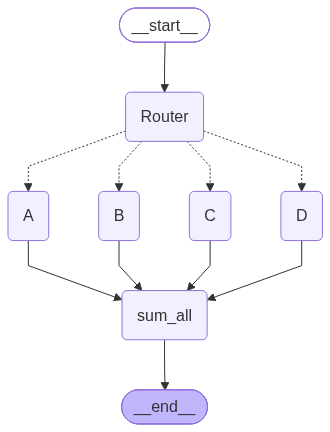

In [17]:
graph

In [18]:
print(graph.invoke({"inputs": "aa产品"}))

{'inputs': '处理产品问题', 'outputs': '处理产品问题'}


In [19]:
print(graph.invoke({"inputs": "aa售后"}))

{'inputs': '处理售后问题', 'outputs': '处理售后问题'}


In [20]:
print(graph.invoke({"inputs": "aa政策"}))

{'inputs': '处理政策问题', 'outputs': '处理政策问题'}


In [21]:

print(graph.invoke({"inputs": "aa其他"}))

{'inputs': '正在转人工处理', 'outputs': '正在转人工处理'}


## 节点中调用模型

In [40]:
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv

load_dotenv()
model = init_chat_model("gpt-4o")

In [41]:
from langgraph.graph import MessagesState # 使用默认的状态变量，里面有一个messages字段用来记录消息列表

def call_model(state:MessagesState):
    messages = state["messages"] #[{"role": "user", "content": "你好,你是谁？"}]
    response = model.invoke(messages) # 调用模型 # AIMessage
    return {"messages": response} # 在上一个messages的基础上，追加模型返回的response内容
    

In [42]:
builder = StateGraph(MessagesState)
builder.add_node("call_model", call_model)

builder.add_edge(START, "call_model")
builder.add_edge("call_model", END)

# 生成图，希望图具有记忆能力，开启checkpointer
from langgraph.checkpoint.memory import InMemorySaver
checkpionter= InMemorySaver() 
graph = builder.compile(checkpointer=checkpionter)

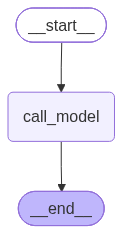

In [43]:
graph

In [29]:
res = graph.invoke({"messages": [{"role": "user", "content": "你好,你是谁？"}]})
for msg in res["messages"]:
    print(msg)

content='你好,你是谁？' additional_kwargs={} response_metadata={} id='325bab48-a3a4-4b70-8c7a-ca68522f5458'
content='你好！我是一个人工智能助手，旨在回答你的问题并帮助你获取信息。有什么我可以帮助你的吗？' additional_kwargs={'refusal': None} response_metadata={'token_usage': {'completion_tokens': 26, 'prompt_tokens': 12, 'total_tokens': 38, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': None, 'text_tokens': None, 'image_tokens': 0}, 'compute_units': None, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None, 'video_tokens': 0}, 'cost': 0.00029, 'is_byok': False, 'cost_details': {'upstream_inference_cost': 0.00029, 'upstream_inference_prompt_cost': 3e-05, 'upstream_inference_completions_cost': 0.00026}}, 'model_provider': 'openai', 'model_name': 'openai/gpt-4o', 'system_fingerprint': 'fp_7bfd4ce6e1', 'id': 'gen-1792050432-xeKtdK0ZCYWZoSKhtd5z', 'service_tier': 'default

In [32]:
for chunk in graph.stream({"messages": [{"role": "user", "content": "河北的省会在哪？"}]}, stream_mode="messages"):
    print(chunk[0].content, end="", flush=True)

河北省的省会是石家庄市。

In [33]:
for chunk in graph.stream({"messages": [{"role": "user", "content": "那么河南呢？"}]}, stream_mode="messages"):
    print(chunk[0].content, end="", flush=True)

河南是中国的一个省，位于中国中东部。它是中国的人口大省之一，有着悠久的历史和丰富的文化遗产。河南是中华文明的重要发源地之一，拥有许多历史名城如洛阳和开封。少林寺、龙门石窟和殷墟是河南著名的旅游景点。此外，河南也是农业和工业的重要基地。是否需要更多关于河南的信息？

In [45]:
config = {
    "configurable":{"thread_id":"1"}
}

res = graph.invoke({"messages": [{"role": "user", "content": "河北的省会在哪？"}]}, config=config)
for msg in res["messages"]:
    print(msg)

content='河北的省会在哪？' additional_kwargs={} response_metadata={} id='fbc39c77-538f-4696-9589-83825966081e'
content='河北省的省会是石家庄市。' additional_kwargs={'refusal': None} response_metadata={'token_usage': {'completion_tokens': 11, 'prompt_tokens': 13, 'total_tokens': 24, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': None, 'text_tokens': None, 'image_tokens': 0}, 'compute_units': None, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None, 'video_tokens': 0}, 'cost': 0.0001425, 'is_byok': False, 'cost_details': {'upstream_inference_cost': 0.0001425, 'upstream_inference_prompt_cost': 3.25e-05, 'upstream_inference_completions_cost': 0.00011}}, 'model_provider': 'openai', 'model_name': 'openai/gpt-4o', 'system_fingerprint': 'fp_91c2c6d730', 'id': 'gen-1792051124-n9uVYK887AlmGKaWS1P2', 'service_tier': 'default', 'finish_reason': 'st

In [46]:
res = graph.invoke({"messages": [{"role": "user", "content": "那么河南呢？"}]}, config=config)
for msg in res["messages"]:
    print(msg)

content='河北的省会在哪？' additional_kwargs={} response_metadata={} id='fbc39c77-538f-4696-9589-83825966081e'
content='河北省的省会是石家庄市。' additional_kwargs={'refusal': None} response_metadata={'token_usage': {'completion_tokens': 11, 'prompt_tokens': 13, 'total_tokens': 24, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': None, 'text_tokens': None, 'image_tokens': 0}, 'compute_units': None, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None, 'video_tokens': 0}, 'cost': 0.0001425, 'is_byok': False, 'cost_details': {'upstream_inference_cost': 0.0001425, 'upstream_inference_prompt_cost': 3.25e-05, 'upstream_inference_completions_cost': 0.00011}}, 'model_provider': 'openai', 'model_name': 'openai/gpt-4o', 'system_fingerprint': 'fp_91c2c6d730', 'id': 'gen-1792051124-n9uVYK887AlmGKaWS1P2', 'service_tier': 'default', 'finish_reason': 'st

## 断点恢复

In [47]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver

# ==========================================
# 1. 模拟真实世界的不可预测故障
# ==========================================
# 全局变量：模拟外部环境。第一次运行时为 True (触发崩溃)，恢复时设为 False
SIMULATE_NETWORK_CRASH = True 

class WorkflowState(TypedDict):
    logs: list[str]

# ==========================================
# 2. 定义多节点工作流
# ==========================================
async def node_a(state: WorkflowState) -> WorkflowState:
    logs = state.get("logs", []) + ["[Node A]  步骤 A 成功。状态已自动持久化。"]
    return {"logs": logs}

async def node_b(state: WorkflowState) -> WorkflowState:
    logs = state.get("logs", []) + ["[Node B]  正在执行核心逻辑..."]
    
    #  模拟不可预测的崩溃：不需要在 compile 时指定，崩溃就发生在节点内部
    if SIMULATE_NETWORK_CRASH:
        logs.append("[Node B]  遭遇突发网络错误，进程即将崩溃！")
        # 在实际场景中，这可能是 requests.exceptions.ConnectionError 或内存溢出
        raise RuntimeError("BOOM! Node B 内部发生不可预测的崩溃")
    
    logs.append("[Node B]  步骤 B 成功。")
    return {"logs": logs}

async def node_c(state: WorkflowState) -> WorkflowState:
    logs = state.get("logs", []) + ["[Node C]  步骤 C 成功。工作流结束。"]
    return {"logs": logs}

# ==========================================
# 3. 构建图 (仅配置 Checkpointer)
# ==========================================
builder = StateGraph(WorkflowState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", "node_c")
builder.add_edge("node_c", END)

# 只要配置了 Checkpointer，LangGraph 就会在每个节点成功后自动保存状态
checkpointer = MemorySaver()
graph = builder.compile(checkpointer=checkpointer)

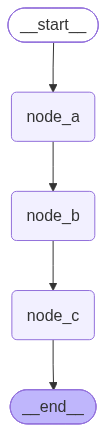

In [48]:
graph

In [49]:
# ==========================================
# 4. 演示：意外崩溃、检查断点、自动恢复
# ==========================================

global SIMULATE_NETWORK_CRASH
thread_id = "random_crash_thread"
config = {"configurable": {"thread_id": thread_id}}

print(" === 第一阶段：首次运行，遭遇意外崩溃 ===")
try:
    await graph.ainvoke({"logs": []}, config)
except RuntimeError as e:
    print(f" [系统捕获到崩溃] {e}")
    print(" 进程中断，但请观察 Checkpointer 是否保护了已完成的工作...\n")

 === 第一阶段：首次运行，遭遇意外崩溃 ===
 [系统捕获到崩溃] BOOM! Node B 内部发生不可预测的崩溃
 进程中断，但请观察 Checkpointer 是否保护了已完成的工作...



In [50]:
print(" === 第二阶段：检查系统停在了哪里 ===")
# 重新加载状态
snapshot = graph.get_state(config)

print(f" 崩溃前保存的日志:")
for log in snapshot.values.get("logs", []):
    print(log)
    
print(f"\n 接下来将要执行的节点 (next): {snapshot.next}")
print(" 解析：Node A 已成功并保存。Node B 崩溃了，所以断点停留在 Node B。\n")



 === 第二阶段：检查系统停在了哪里 ===
 崩溃前保存的日志:
[Node A]  步骤 A 成功。状态已自动持久化。

 接下来将要执行的节点 (next): ('node_b',)
 解析：Node A 已成功并保存。Node B 崩溃了，所以断点停留在 Node B。



In [51]:
# ==========================================
# 第三阶段：恢复并继续执行
# ==========================================

SIMULATE_NETWORK_CRASH = False

final_result = await graph.ainvoke(None, config) # 自动从上一次中断的位置继续执行

print(final_result)

{'logs': ['[Node A]  步骤 A 成功。状态已自动持久化。', '[Node B]  正在执行核心逻辑...', '[Node B]  步骤 B 成功。', '[Node C]  步骤 C 成功。工作流结束。']}
